/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Model Valid: True


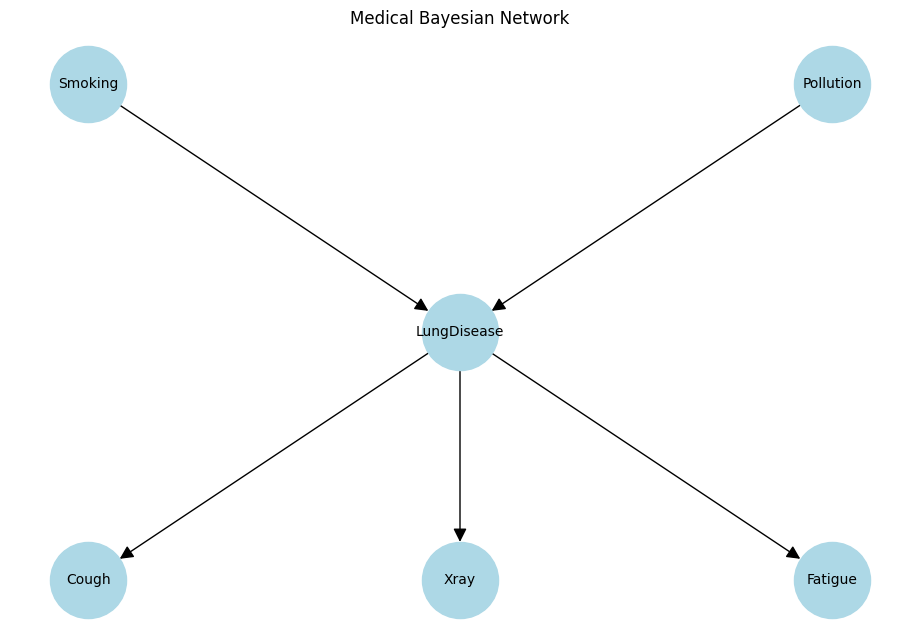


EXACT INFERENCE
+----------------+--------------------+
| LungDisease    |   phi(LungDisease) |
+================+====================+
| LungDisease(0) |             0.2746 |
+----------------+--------------------+
| LungDisease(1) |             0.7254 |
+----------------+--------------------+
Probability of Lung Disease = 0.7254

WITH SMOKING
P(Lung Disease | Xray, Cough, Smoking=Yes) = 0.8601

WITHOUT SMOKING
P(Lung Disease | Xray, Cough, Smoking=No) = 0.5745

FORWARD SAMPLING DATA
   Smoking  Pollution  LungDisease  Cough  Xray  Fatigue
0        0          0            0      0     0        0
1        1          0            0      0     0        0
2        1          0            0      0     0        0
3        0          0            0      0     0        0
4        0          0            0      0     0        0

REJECTION SAMPLING
Estimated probability = 0.7287

COMPARISON TABLE
               Method  Probability
0     Exact Inference     0.725371
1  Rejection Sampling     0.

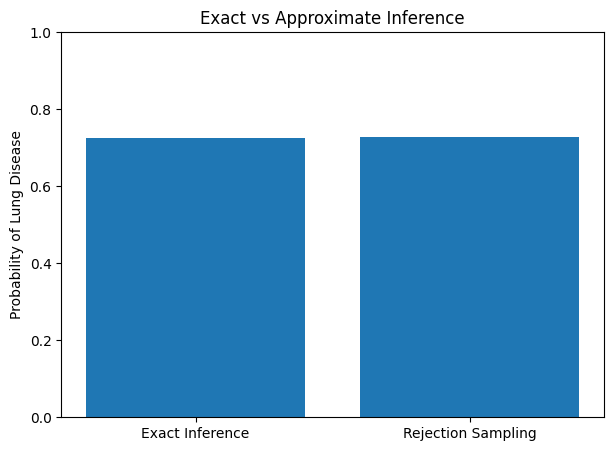


CONVERGENCE TABLE
   Sample Size  Estimated Probability
0          100               1.000000
1          500               0.700000
2         1000               0.672414
3         5000               0.747541
4        10000               0.714516
5        20000               0.735864
6        50000               0.728485
7       100000               0.728731


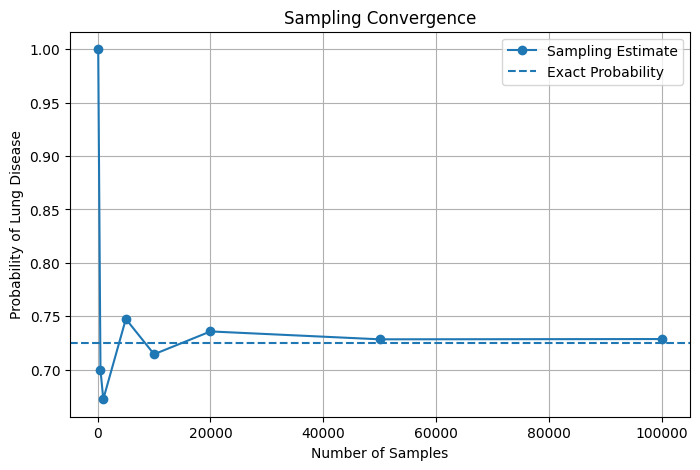


SAMPLE STATISTICS
Xray  Cough
0     0        0.008220
      1        0.066769
1     0        0.224513
      1        0.728731
Name: LungDisease, dtype: float64

EXPERIMENT COMPLETED SUCCESSFULLY


In [28]:

# EXPERIMENT 24: GRAPHICAL MODEL SAMPLING AND PROBABILISTIC INFERENCE

!pip install -q pgmpy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

# --------------------------------------------------
# STEP 1: CONSTRUCT THE BAYESIAN NETWORK
# --------------------------------------------------

model = DiscreteBayesianNetwork([
    ('Smoking', 'LungDisease'),
    ('Pollution', 'LungDisease'),
    ('LungDisease', 'Cough'),
    ('LungDisease', 'Xray'),
    ('LungDisease', 'Fatigue')
])

# State convention: 0 = No, 1 = Yes

cpd_smoking = TabularCPD(
    variable='Smoking',
    variable_card=2,
    values=[[0.7], [0.3]]
)

cpd_pollution = TabularCPD(
    variable='Pollution',
    variable_card=2,
    values=[[0.6], [0.4]]
)

cpd_lung = TabularCPD(
    variable='LungDisease',
    variable_card=2,
    values=[
        [0.99, 0.90, 0.90, 0.70],
        [0.01, 0.10, 0.10, 0.30]
    ],
    evidence=['Smoking', 'Pollution'],
    evidence_card=[2, 2]
)

cpd_cough = TabularCPD(
    variable='Cough',
    variable_card=2,
    values=[
        [0.80, 0.30],
        [0.20, 0.70]
    ],
    evidence=['LungDisease'],
    evidence_card=[2]
)

cpd_xray = TabularCPD(
    variable='Xray',
    variable_card=2,
    values=[
        [0.90, 0.20],
        [0.10, 0.80]
    ],
    evidence=['LungDisease'],
    evidence_card=[2]
)

cpd_fatigue = TabularCPD(
    variable='Fatigue',
    variable_card=2,
    values=[
        [0.70, 0.40],
        [0.30, 0.60]
    ],
    evidence=['LungDisease'],
    evidence_card=[2]
)

model.add_cpds(
    cpd_smoking,
    cpd_pollution,
    cpd_lung,
    cpd_cough,
    cpd_xray,
    cpd_fatigue
)

print("Model Valid:", model.check_model())

# --------------------------------------------------
# STEP 2: VISUALIZE THE BAYESIAN NETWORK
# --------------------------------------------------

plt.figure(figsize=(9, 6))

G = nx.DiGraph()
G.add_edges_from(model.edges())

pos = {
    'Smoking': (0, 2),
    'Pollution': (2, 2),
    'LungDisease': (1, 1),
    'Cough': (0, 0),
    'Xray': (1, 0),
    'Fatigue': (2, 0)
}

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=3000,
    node_color='lightblue',
    font_size=10,
    arrows=True,
    arrowsize=20
)

plt.title("Medical Bayesian Network")
plt.show()

# --------------------------------------------------
# STEP 3: EXACT INFERENCE USING VARIABLE ELIMINATION
# --------------------------------------------------

inference = VariableElimination(model)

# Given a positive X-ray and cough
query = inference.query(
    variables=['LungDisease'],
    evidence={'Xray': 1, 'Cough': 1}
)

exact_probability = query.values[1]

print("\nEXACT INFERENCE")
print(query)
print("Probability of Lung Disease =", round(exact_probability, 4))

# Does smoking change the answer?
query_smoker = inference.query(
    variables=['LungDisease'],
    evidence={'Xray': 1, 'Cough': 1, 'Smoking': 1}
)

query_non_smoker = inference.query(
    variables=['LungDisease'],
    evidence={'Xray': 1, 'Cough': 1, 'Smoking': 0}
)

print("\nWITH SMOKING")
print("P(Lung Disease | Xray, Cough, Smoking=Yes) =",
      round(query_smoker.values[1], 4))

print("\nWITHOUT SMOKING")
print("P(Lung Disease | Xray, Cough, Smoking=No) =",
      round(query_non_smoker.values[1], 4))

# --------------------------------------------------
# STEP 4: FORWARD SAMPLING
# --------------------------------------------------

def forward_sampling(n):

    smoking = np.random.choice([0, 1], n, p=[0.7, 0.3])
    pollution = np.random.choice([0, 1], n, p=[0.6, 0.4])

    lung = np.zeros(n, dtype=int)

    for i in range(n):
        if smoking[i] == 0 and pollution[i] == 0:
            p = 0.01
        elif smoking[i] == 0 and pollution[i] == 1:
            p = 0.10
        elif smoking[i] == 1 and pollution[i] == 0:
            p = 0.10
        else:
            p = 0.30

        lung[i] = np.random.choice([0, 1], p=[1-p, p])

    cough = np.zeros(n, dtype=int)
    xray = np.zeros(n, dtype=int)
    fatigue = np.zeros(n, dtype=int)

    for i in range(n):

        if lung[i] == 1:
            cough[i] = np.random.choice([0, 1], p=[0.3, 0.7])
            xray[i] = np.random.choice([0, 1], p=[0.2, 0.8])
            fatigue[i] = np.random.choice([0, 1], p=[0.4, 0.6])
        else:
            cough[i] = np.random.choice([0, 1], p=[0.8, 0.2])
            xray[i] = np.random.choice([0, 1], p=[0.9, 0.1])
            fatigue[i] = np.random.choice([0, 1], p=[0.7, 0.3])

    return pd.DataFrame({
        'Smoking': smoking,
        'Pollution': pollution,
        'LungDisease': lung,
        'Cough': cough,
        'Xray': xray,
        'Fatigue': fatigue
    })

# Generate samples
np.random.seed(42)

samples = forward_sampling(100000)

print("\nFORWARD SAMPLING DATA")
print(samples.head())

# --------------------------------------------------
# STEP 5: REJECTION SAMPLING
# --------------------------------------------------

# Evidence: Xray=Yes and Cough=Yes
# Target: LungDisease=Yes

def rejection_sampling(data, evidence, target, target_value=1):

    accepted = data.copy()

    for variable, value in evidence.items():
        accepted = accepted[accepted[variable] == value]

    if len(accepted) == 0:
        return np.nan

    return np.mean(accepted[target] == target_value)

estimate = rejection_sampling(
    samples,
    {'Xray': 1, 'Cough': 1},
    'LungDisease'
)

print("\nREJECTION SAMPLING")
print("Estimated probability =", round(estimate, 4))

# --------------------------------------------------
# STEP 6: COMPARE EXACT AND APPROXIMATE RESULTS
# --------------------------------------------------

results = pd.DataFrame({
    'Method': ['Exact Inference', 'Rejection Sampling'],
    'Probability': [exact_probability, estimate]
})

print("\nCOMPARISON TABLE")
print(results)

plt.figure(figsize=(7, 5))

plt.bar(
    results['Method'],
    results['Probability']
)

plt.ylabel("Probability of Lung Disease")
plt.title("Exact vs Approximate Inference")
plt.ylim(0, 1)

plt.show()

# --------------------------------------------------
# STEP 7: CONVERGENCE ANALYSIS
# --------------------------------------------------

sample_sizes = [100, 500, 1000, 5000, 10000, 20000, 50000, 100000]

convergence = []

for size in sample_sizes:

    subset = samples.iloc[:size]

    estimate = rejection_sampling(
        subset,
        {'Xray': 1, 'Cough': 1},
        'LungDisease'
    )

    convergence.append(estimate)

convergence_df = pd.DataFrame({
    'Sample Size': sample_sizes,
    'Estimated Probability': convergence
})

print("\nCONVERGENCE TABLE")
print(convergence_df)

plt.figure(figsize=(8, 5))

plt.plot(
    sample_sizes,
    convergence,
    marker='o',
    label='Sampling Estimate'
)

plt.axhline(
    exact_probability,
    linestyle='--',
    label='Exact Probability'
)

plt.xlabel("Number of Samples")
plt.ylabel("Probability of Lung Disease")
plt.title("Sampling Convergence")
plt.legend()
plt.grid(True)

plt.show()

# --------------------------------------------------
# STEP 8: PANDAS ANALYSIS OF SAMPLES
# --------------------------------------------------

print("\nSAMPLE STATISTICS")

print(samples.groupby(['Xray', 'Cough'])['LungDisease'].mean())

print("\nEXPERIMENT COMPLETED SUCCESSFULLY")
